# Energy-preserving Bayesian operator inference - 2D Burgers

Same method as problems 1 and 2, on the data of `0 - Data generation - Burgers 2D.ipynb`.
Two things are specific to this problem. It is viscous, so the certificates of section 4 have
something to certify again, unlike in problem 2; and the state is a field on a square, so the
predictions are shown as 2D fields in section 7.


## 0. Setup

In [1]:
import numpy as np
import time, warnings
from math import comb
from scipy.linalg import cho_factor, cho_solve, cholesky, null_space, solve
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.stats import beta as beta_dist
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
import cvxpy as cp
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

D = np.load("data_Burgers2D.npz")

r = int(D["r"])            # reduced dimension, as set in the data notebook
L = D["train_params"].shape[0]
V = D["V"][:, :r]; q_bar = D["q_bar"]
x = D["x"]; y = D["y"]; dx = float(D["dx"]); NX = int(D["nx"])
KAPPA = float(D["kappa"]); NU = float(D["nu"])
t_truth = D["t_truth"]; t_est = D["t_est"]; m_prime = t_est.size
obs_times = D["obs_times"]; Qobs = D["snapshots_compressed"][:, :r, :]
TRAIN = D["train_params"]; TEST = D["test_params"]
TRUTH_TR = D["truth_train"]; TRUTH_TE = D["truth_test"]
T_TRAIN = float(D["t_train"][1])        # 2, read from the data rather than hard coded
T_FINAL = float(D["t_final"])           # 4

dof = 1 + r + r*(r+1)//2     # d = length of the feature vector; no input, so no B block
n   = r*dof                  # length of theta
n_c = comb(r+2, 3)           # number of EP constraints

PAIRS_IJ = np.triu_indices(r)
PAIRS    = list(zip(*PAIRS_IJ))

def kron_compact(q):
    """The compact Kronecker product of q with itself: the products q_j q_k, j <= k."""
    return np.outer(q, q)[PAIRS_IJ]

N_SAMP = 3000      # posterior draws
N_PRED = 200       # draws integrated for prediction, as in problem 1
DELTA  = 0.0       # certificate margin
SEED   = 20261026

print(f"kappa = {KAPPA:g},  nu = {NU:g},  N_dof = {NX*NX}")
print(f"r = {r},  d = {dof},  n = r*d = {n},  n_c = {n_c}")
print(f"L = {L} trajectories,  m = {obs_times.shape[1]} snapshots,  m' = {m_prime} estimation times")
print(f"train on [0, {T_TRAIN:g}], predict to {T_FINAL:g}")

kappa = 0.2,  nu = 0.002,  N_dof = 2500
r = 6,  d = 28,  n = r*d = 168,  n_c = 56
L = 5 trajectories,  m = 30 snapshots,  m' = 60 estimation times
train on [0, 2], predict to 4


## 1. Gaussian process state and derivative estimates

One independent GP per reduced coordinate, squared-exponential kernel plus noise;
differentiation is linear, so with $\mathbf K=\kappa(\mathbf t,\mathbf t)+\sigma_n^2\mathbf I$,

$$
\tilde z(t') = \partial_{t'}\kappa(t',\mathbf t)\,\mathbf K^{-1}\mathbf y,
\qquad
\operatorname{Var}\,\tilde z(t') = \partial_{t'}\partial_{t''}\kappa(t',t'')\big|_{t''=t'}
 - \partial_{t'}\kappa(t',\mathbf t)\,\mathbf K^{-1}\partial_{t'}\kappa(t',\mathbf t)^\top .
\tag{1}
$$

The window is $[0,2]$ and the $m=150$ observations are spaced $2/149\approx0.013$ apart, so
the length-scale floor is set at $0.01$, just below the spacing: that rules out a fit which
interpolates the noise.

In [2]:
def fit_gp(t, y, seed=1):
    # kappa(t,t') = sf2 * exp(-(t-t')^2 / (2 ell^2)) + sn2 delta_{t,t'}.
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * RBF(0.3, (1e-2, 1e1))
         + WhiteKernel(1e-4, (1e-10, 1e0)))
    g = GaussianProcessRegressor(kernel=k, normalize_y=False,
                                 n_restarts_optimizer=3, random_state=seed)
    return g.fit(t[:, None], y)

def gp_estimates(g, t_obs, y, t_new):
    """State estimate, derivative estimate and derivative variance at t_new, eq. (1)."""
    sf2 = float(g.kernel_.k1.k1.constant_value)
    ell = float(g.kernel_.k1.k2.length_scale)
    sn2 = float(g.kernel_.k2.noise_level)

    Dm = t_new[:, None] - t_obs[None, :]
    K  = sf2*np.exp(-0.5*((t_obs[:, None] - t_obs[None, :])/ell)**2) \
         + sn2*np.eye(t_obs.size)
    Ks = sf2*np.exp(-0.5*(Dm/ell)**2)
    Kd = Ks * (-Dm/ell**2)                      # d kappa / dt'

    K_factored = cho_factor(K, lower=True)
    alpha      = cho_solve(K_factored, y)
    explained  = np.sum(Kd * cho_solve(K_factored, Kd.T).T, axis=1)
    return Ks @ alpha, Kd @ alpha, np.maximum(sf2/ell**2 - explained, 1e-12)

t0 = time.time()
STATE = np.zeros((L, r, m_prime)); DERIV = np.zeros_like(STATE); DVAR = np.zeros_like(STATE)
ELL = np.zeros((L, r))
for l in range(L):
    for i in range(r):
        g = fit_gp(obs_times[l], Qobs[l, i])
        STATE[l,i], DERIV[l,i], DVAR[l,i] = gp_estimates(g, obs_times[l], Qobs[l,i], t_est)
        ELL[l,i] = float(g.kernel_.k1.k2.length_scale)
print(f"{L*r} GP fits in {time.time()-t0:.1f} s")
print(f"length scales in [{ELL.min():.3f}, {ELL.max():.3f}], observation spacing "
      f"{T_TRAIN/(obs_times.shape[1]-1):.4f}")
print(f"derivative std: {np.sqrt(DVAR).min():.3e} .. {np.sqrt(DVAR).max():.3e}")

30 GP fits in 1.1 s
length scales in [0.602, 3.250], observation spacing 0.0690
derivative std: 3.027e-03 .. 1.336e-01


### 1.1 How good are the derivatives, and is the GP honest about it?

Everything downstream regresses onto $\tilde z$, so its accuracy caps the method. The reference
solution is available here, so the estimates can be scored against it --- a diagnostic, not
something the method may use. Two numbers matter: the error itself, and its ratio to the
standard deviation the GP reports, since that standard deviation is what enters the posterior
as a weight. A ratio near one means the weights are honest.

In [3]:
# True reduced coordinates and their derivatives, by central differences on the dense grid.
Qh_true  = np.array([V.T @ (TRUTH_TR[l] - q_bar[:, None]) for l in range(L)])
dQh_true = np.gradient(Qh_true, t_truth[1]-t_truth[0], axis=2)

rel_err = np.zeros((L, r)); abs_err = np.zeros((L, r)); deriv_rms = np.zeros((L, r))
for l in range(L):
    for i in range(r):
        target = np.interp(t_est, t_truth, dQh_true[l, i])
        resid  = DERIV[l, i] - target
        abs_err[l, i]   = np.linalg.norm(resid)/np.sqrt(resid.size)
        deriv_rms[l, i] = np.linalg.norm(target)/np.sqrt(target.size)
        rel_err[l, i]   = np.linalg.norm(resid)/max(np.linalg.norm(target), 1e-12)

gp_std = np.sqrt(DVAR).mean(axis=2)          # what the GP claims, per trajectory and coordinate

def row(name, v, fmt="7.3f"):
    print(f"  {name:<16s}" + " ".join(format(val, fmt) for val in v))
print("per coordinate, median over the five trajectories:")
row("coordinate",  np.arange(1, r+1), "7.0f")
row("rms deriv",   np.median(deriv_rms, axis=0))
row("rms error",   np.median(abs_err, axis=0))
row("rel error",   np.median(rel_err, axis=0))
row("error/GP std", np.median(abs_err/gp_std, axis=0))
print(f"\nmedian relative error {np.median(rel_err):.4f}, "
      f"median error/GP std {np.median(abs_err/gp_std):.2f}")
print("-> the derivatives are good to a few percent and the GP's own standard deviation is")
print("   the right size, so the weights W = 1/Var are not overconfident.")

per coordinate, median over the five trajectories:
  coordinate            1       2       3       4       5       6
  rms deriv         3.046   1.618   0.639   1.582   0.618   0.734
  rms error         0.017   0.013   0.013   0.024   0.037   0.026
  rel error         0.004   0.008   0.025   0.013   0.044   0.034
  error/GP std      0.896   0.871   1.468   1.456   1.724   1.219

median relative error 0.0164, median error/GP std 1.24
-> the derivatives are good to a few percent and the GP's own standard deviation is
   the right size, so the weights W = 1/Var are not overconfident.


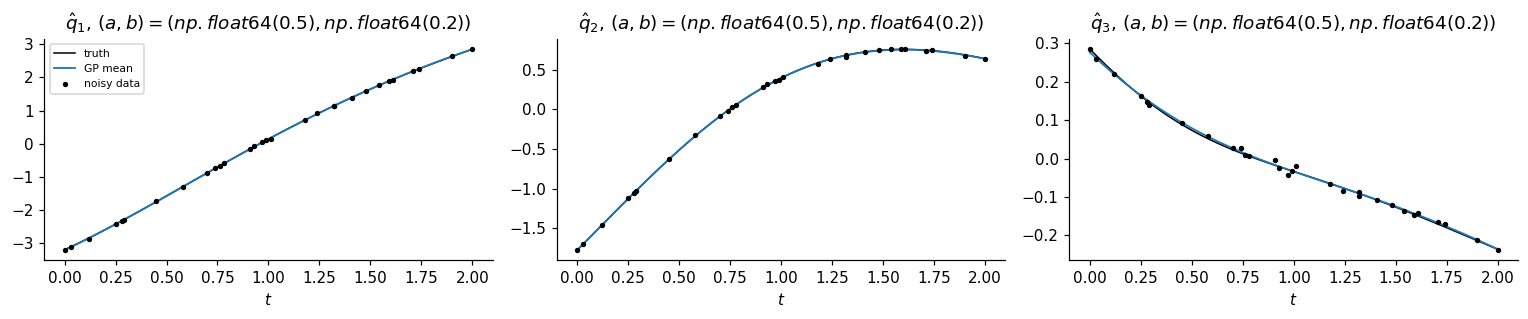

In [4]:
# The three leading coordinates of one trajectory: data, GP state, truth.
l_show = 4
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
train_mask = t_truth <= T_TRAIN
for i, ax in enumerate(axes):
    ax.plot(t_truth[train_mask], Qh_true[l_show, i, train_mask], "k", lw=1, label="truth")
    ax.plot(t_est, STATE[l_show, i], "C0", lw=1.2, label="GP mean")
    ax.plot(obs_times[l_show], Qobs[l_show, i], "ko", ms=2.5, label="noisy data")
    ax.set(xlabel="$t$", title=rf"$\hat q_{{{i+1}}}$, $(a,b)={tuple(TRAIN[l_show])}$")
    if i == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 2. The operator posterior

With $\mathbf d(\hat{\mathbf q})=[1;\ \hat{\mathbf q};\ \hat{\mathbf q}\,\hat\otimes\,\hat{\mathbf q}]\in\mathbb R^{d}$
and $\widetilde{\mathbf D}$ the features at all estimation times of all trajectories, each row
$\hat{\mathbf o}_i$ has the Gaussian posterior

$$
\hat{\mathbf o}_i\mid\text{data}\sim\mathcal N(\boldsymbol\mu_i,\boldsymbol\Sigma_i),
\qquad
\boldsymbol\Sigma_i=\bigl(\widetilde{\mathbf D}^\top\mathbf W_i\widetilde{\mathbf D}+\boldsymbol\Gamma_i^2\bigr)^{-1},
\qquad
\boldsymbol\mu_i=\boldsymbol\Sigma_i\widetilde{\mathbf D}^\top\mathbf W_i\tilde{\mathbf z}_i .
\tag{2}
$$

$\boldsymbol\Phi=\operatorname{blkdiag}(\widetilde{\mathbf D},\dots,\widetilde{\mathbf D})$ is
never formed: $\boldsymbol\Phi^\top\mathbf W\boldsymbol\Phi$ is block diagonal with blocks
$\widetilde{\mathbf D}^\top\mathbf W_i\widetilde{\mathbf D}$, which is all any expression below
needs.

In [5]:
def features(q):
    """The feature vector d(q) = [1; q; q (x) q].  No input term in this problem."""
    return np.concatenate(([1.0], q, kron_compact(q)))

Dtil = np.zeros((L*m_prime, dof))
for l in range(L):
    for k in range(m_prime):
        Dtil[l*m_prime + k] = features(STATE[l, :, k])

DWD = np.zeros((r, dof, dof)); DWz = np.zeros((r, dof))
for i in range(r):
    for l in range(L):
        Dl = Dtil[l*m_prime:(l+1)*m_prime]
        wl = 1.0/DVAR[l, i]
        DWD[i] += Dl.T @ (wl[:, None]*Dl)
        DWz[i] += Dl.T @ (wl*DERIV[l, i])

zvec = np.concatenate([DERIV[:, i, :].reshape(-1) for i in range(r)])
wvec = np.concatenate([1.0/DVAR[:, i, :].reshape(-1) for i in range(r)])
Nobs = zvec.size; z_W_z = zvec @ (wvec*zvec); logdet_W = float(np.sum(np.log(wvec)))

def block_apply(X):
    """Phi' W Phi applied to X, block by block."""
    Y = np.empty_like(X)
    for i in range(r):
        sl = slice(i*dof, (i+1)*dof)
        Y[sl] = DWD[i] @ X[sl]
    return Y

print(f"D~ {Dtil.shape}, cond {np.linalg.cond(Dtil):.2e}")
print(f"N = {Nobs} derivative observations,  n = {n} unknowns")

D~ (300, 28), cond 7.06e+03
N = 1800 derivative observations,  n = 168 unknowns


## 3. Energy preservation

### 3.1 The constraint

$\widehat{\mathbf H}$ is energy preserving iff $H_{ijk}+H_{jik}+H_{kij}=0$ for all $i,j,k$.
Collected into a matrix acting on $\boldsymbol\theta=[\hat{\mathbf o}_1;\dots;\hat{\mathbf o}_r]$,

$$
\widehat{\mathbf H}\in\mathcal H_{\mathrm{EP}}\iff \mathbf C\boldsymbol\theta=\mathbf 0,
\qquad \mathbf C\in\mathbb R^{n_c\times n},\quad \operatorname{rank}\mathbf C=n_c .
\tag{3}
$$

In [6]:
def index_of_h(i, j, k):
    """Where the compact coefficient h_{i,jk} sits inside theta.

    Row i starts at i*dof as [c_i, A_i (r), H_i (compact)], so the quadratic part starts at
    i*dof + 1 + r.  h_{i,jk} = h_{i,kj}, so the pair is sorted before being looked up.
    """
    return i*dof + 1 + r + PAIRS.index((min(j, k), max(j, k)))

rows = []
for a in range(r):                                   # q_a^3
    row_ = np.zeros(n); row_[index_of_h(a, a, a)] += 1.0; rows.append(row_)
for a in range(r):
    for c in range(a+1, r):
        row_ = np.zeros(n)                           # q_a^2 q_c
        row_[index_of_h(a, a, c)] += 1.0; row_[index_of_h(c, a, a)] += 1.0; rows.append(row_)
        row_ = np.zeros(n)                           # q_a q_c^2
        row_[index_of_h(a, c, c)] += 1.0; row_[index_of_h(c, a, c)] += 1.0; rows.append(row_)
for a in range(r):                                   # q_a q_b q_c, all distinct
    for b in range(a+1, r):
        for c in range(b+1, r):
            row_ = np.zeros(n)
            row_[index_of_h(a, b, c)] += 1.0
            row_[index_of_h(b, a, c)] += 1.0
            row_[index_of_h(c, a, b)] += 1.0
            rows.append(row_)

Cmat = np.array(rows)
Tker = null_space(Cmat)
gram = Cmat @ Cmat.T
print(f"C: {Cmat.shape},  expected n_c = {n_c},  rank = {np.linalg.matrix_rank(Cmat)}")
print(f"ker C: {Tker.shape} (expected {n - n_c}),  ||C T|| = {np.abs(Cmat@Tker).max():.2e}")
print(f"C C' diagonal: max off-diagonal {np.abs(gram - np.diag(np.diag(gram))).max():.1e}, "
      f"diagonal entries {sorted(set(np.diag(gram).astype(int)))}")

C: (56, 168),  expected n_c = 56,  rank = 56
ker C: (168, 112) (expected 112),  ||C T|| = 2.22e-16
C C' diagonal: max off-diagonal 0.0e+00, diagonal entries [np.int64(1), np.int64(2), np.int64(3)]


### 3.2 Prior scales by marginal likelihood

One scale per operator block ($\hat{\mathbf c},\widehat{\mathbf A},\widehat{\mathbf H}$), chosen
by maximising the closed-form log evidence

$$
\log p(\tilde{\mathbf z})
 = -\tfrac N2\log2\pi + \tfrac12\log|\mathbf W| + \tfrac12\log|\mathbf P_0|
 - \tfrac12\log|\mathbf P|
 - \tfrac12\bigl(\tilde{\mathbf z}^\top\mathbf W\tilde{\mathbf z}-\boldsymbol\mu^\top\mathbf P\boldsymbol\mu\bigr),
\tag{4}
$$

with $\mathbf P=\boldsymbol\Phi^\top\mathbf W\boldsymbol\Phi+\mathbf P_0$, applied in the
coordinates of $\ker\mathbf C$: $\boldsymbol\Phi\to\boldsymbol\Phi\mathbf T$ and
$\mathbf P_0=\mathbf T^\top\operatorname{diag}(\boldsymbol\gamma^2)\mathbf T$.

In [7]:
# Which operator block each component of theta belongs to: 0 = c, 1 = A, 2 = H.
block_of = np.tile(np.concatenate(([0], np.full(r, 1), np.full(r*(r+1)//2, 2))), r)

PhiT_W_PhiT = Tker.T @ block_apply(Tker)
PhiT_W_z    = Tker.T @ np.concatenate([DWz[i] for i in range(r)])
M_block     = [Tker[block_of == b].T @ Tker[block_of == b] for b in (0, 1, 2)]

def log_evidence(gam):
    """Eq. (4) in the coordinates of ker C."""
    P0 = sum((gam[b]**2)*M_block[b] for b in range(3))
    P  = PhiT_W_PhiT + P0
    sign0, logdet_P0 = np.linalg.slogdet(P0)
    signP, logdet_P  = np.linalg.slogdet(P)
    if sign0 <= 0 or signP <= 0:
        return -1e12
    mu_z = solve(P, PhiT_W_z, assume_a="pos")
    return (-0.5*Nobs*np.log(2*np.pi) + 0.5*logdet_W + 0.5*logdet_P0 - 0.5*logdet_P
            - 0.5*(z_W_z - mu_z @ (P @ mu_z)))

t0 = time.time(); best = None
for log_gamma_0 in ([-2.]*3, [0.]*3, [2.]*3):
    result = minimize(lambda lg: -log_evidence(np.exp(lg)), log_gamma_0,
                      method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3, maxfev=2000))
    if best is None or result.fun < best.fun:
        best = result
gamma = np.exp(best.x)
print(f"evidence maximised in {time.time()-t0:.1f} s,  log p(z~) = {-best.fun:.2f}")
for name, g in zip(["c", "A", "H"], gamma):
    print(f"   gamma_{name} = {g:.4f}")

evidence maximised in 0.2 s,  log p(z~) = 4325.66
   gamma_c = 0.7490
   gamma_A = 2.0981
   gamma_H = 7.3117


In [8]:
# --- row posteriors, eq. (2) ---
def prior_scales(gam):
    g_c, g_A, g_H = gam
    one_row = np.concatenate(([g_c], np.full(r, g_A), np.full(r*(r+1)//2, g_H)))
    return np.tile(one_row, r)

gvec = prior_scales(gamma)
Sig = np.zeros((n, n)); mu = np.zeros(n); Lchol = []
for i in range(r):
    block = slice(i*dof, (i+1)*dof)
    Sig_i = np.linalg.inv(DWD[i] + np.diag(gvec[block]**2))
    Sig_i = 0.5*(Sig_i + Sig_i.T)
    Sig[block, block] = Sig_i
    mu[block] = Sig_i @ DWz[i]
    Lchol.append(cholesky(Sig_i + 1e-14*np.eye(dof), lower=True))
print(f"unconstrained posterior: ||C mu|| = {np.linalg.norm(Cmat@mu):.4e}")

unconstrained posterior: ||C mu|| = 1.4841e+00


### 3.3 Conditioning on the constraint, and sampling

$\mathbf C\boldsymbol\theta=\mathbf 0$ is a noise-free measurement:

$$
\mathbf K=\boldsymbol\Sigma\mathbf C^\top(\mathbf C\boldsymbol\Sigma\mathbf C^\top)^{-1},
\qquad
\boldsymbol\mu_c=\boldsymbol\mu-\mathbf K\mathbf C\boldsymbol\mu,
\qquad
\boldsymbol\Sigma_c=\boldsymbol\Sigma-\mathbf K\mathbf C\boldsymbol\Sigma ,
\tag{5}
$$

and a draw is corrected by the same fixed linear map,
$\boldsymbol\theta_c=\boldsymbol\theta-\mathbf K\mathbf C\boldsymbol\theta$.

In [9]:
Sig_Ct     = Sig @ Cmat.T
innovation = Cmat @ Sig_Ct
Kg         = solve(innovation, Sig_Ct.T, assume_a="pos").T
mu_c  = mu  - Kg @ (Cmat @ mu)
Sig_c = Sig - Kg @ Sig_Ct.T

reduced_precision = Tker.T @ np.linalg.inv(Sig) @ Tker
Sig_from_kernel   = Tker @ np.linalg.inv(reduced_precision) @ Tker.T
print(f"||C mu_c||    = {np.linalg.norm(Cmat@mu_c):.3e}")
print(f"max |C Sig_c| = {np.abs(Cmat@Sig_c).max():.3e}")
print(f"max |Sig_c - T(T'Sig^-1T)^-1T'| = {np.abs(Sig_c-Sig_from_kernel).max():.3e}   (equivalence)")

def draw(rng):
    """One draw of the constrained posterior."""
    theta = np.zeros(n)
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        theta[block] = mu[block] + Lchol[i] @ rng.standard_normal(dof)
    return theta - Kg @ (Cmat @ theta)

def unpack(theta):
    """Split theta into (c_hat, A_hat, H_hat), the last compact."""
    O = theta.reshape(r, dof)
    return O[:, 0], O[:, 1:1+r], O[:, 1+r:dof]

rng = np.random.default_rng(SEED)
violation = np.array([np.linalg.norm(Cmat @ draw(rng)) for _ in range(200)])
print(f"\n||C theta_c|| over 200 draws: max {violation.max():.3e}   (exactly EP, draw by draw)")

||C mu_c||    = 2.262e-14
max |C Sig_c| = 2.385e-17
max |Sig_c - T(T'Sig^-1T)^-1T'| = 1.580e-13   (equivalence)

||C theta_c|| over 200 draws: max 2.532e-14   (exactly EP, draw by draw)


In [10]:
def expand_H(H_hat):
    """The full H in R^{r x r^2}, from the compact coefficients h_{i,jk}."""
    H = np.zeros((r, r*r))
    for col, (j, k) in enumerate(PAIRS):
        if j == k:
            H[:, j*r + j] = H_hat[:, col]
        else:
            H[:, j*r + k] = H_hat[:, col]/2
            H[:, k*r + j] = H_hat[:, col]/2
    return H

# Energy preservation of the constrained mean, read in index form: an independent check of C,
# which was assembled from the compact coefficients while the condition below is the definition.
H_mean = expand_H(unpack(mu_c)[2])
worst_index = max(abs(H_mean[i, j*r + k] + H_mean[j, i*r + k] + H_mean[k, i*r + j])
                  for i in range(r) for j in range(r) for k in range(r))
print(f"max |H_ijk + H_jik + H_kij| over all {r**3} triples = {worst_index:.3e}")

rng_check = np.random.default_rng(0)
q_rand = rng_check.standard_normal((200, r))
scale  = np.mean([np.linalg.norm(q)**3 for q in q_rand])
print(f"max |q' H (q (x) q)| over 200 random states    = "
      f"{max(abs(q @ (H_mean @ np.kron(q, q))) for q in q_rand):.3e}")

max |H_ijk + H_jik + H_kij| over all 216 triples = 6.772e-15
max |q' H (q (x) q)| over 200 random states    = 1.724e-13


## 4. Stability certificates

This is the problem where they have something to certify. With $\widehat{\mathbf H}$ energy
preserving, $V=\tfrac12\|\hat{\mathbf q}\|^2$ gives
$\dot V\le-\alpha\|\hat{\mathbf q}\|^2+K\|\hat{\mathbf q}\|$ with
$\alpha=-\lambda_{\max}(\operatorname{sym}\widehat{\mathbf A})$, and measuring the energy about a
centre $\mathbf m$ gives the best rate $\alpha^\star=-t^\star$ from

$$
t^\star=\min_{t,\ \mathbf m}\ t
\quad\text{s.t.}\quad
\operatorname{sym}\widehat{\mathbf A}+\operatorname{sym}\mathbf L_{\mathbf m}\preceq t\,\mathbf I ,
\qquad \mathbf L_{\mathbf m}=2\widehat{\mathbf H}(\mathbf m\otimes\mathbf I),
\tag{6}
$$

and a trapping radius $R_{\mathbf m}=\|\mathbf g(\mathbf m)\|/\alpha^\star$ with
$\mathbf g(\mathbf m)=\hat{\mathbf c}+\widehat{\mathbf A}\mathbf m+\widehat{\mathbf H}(\mathbf m\otimes\mathbf m)$.

The physics permits it: the equation is dissipative, with no forcing, so every trajectory decays
towards zero. What the two tests do with that is the point of this section.

In [11]:
def L_of_m(H, m):
    """L_m = 2 H (m (x) I_r)."""
    return 2 * H @ np.kron(m[:, None], np.eye(r))

def shift_matrices(H):
    """The r symmetric matrices S_j with sym(L_m) = sum_j m_j S_j."""
    return np.array([0.5*(L_of_m(H, e) + L_of_m(H, e).T) for e in np.eye(r)])

def certify(theta):
    """(alpha, alpha_star, m, g(m), number of positive eigenvalues of sym A_hat)."""
    c_hat, A_hat, H_hat = unpack(theta)
    sym_A = 0.5*(A_hat + A_hat.T)
    eigs  = np.linalg.eigvalsh(sym_A)
    alpha = -eigs.max(); n_pos = int((eigs > 0).sum())

    H = expand_H(H_hat); S = shift_matrices(H)
    m_var = cp.Variable(r); t_var = cp.Variable()
    shifted = cp.Constant(sym_A) + sum(m_var[j]*cp.Constant(S[j]) for j in range(r))
    problem = cp.Problem(cp.Minimize(t_var), [shifted << t_var*np.eye(r)])
    try:
        problem.solve(solver=cp.CLARABEL); m = m_var.value
    except Exception:
        m = None
    if m is None:
        return alpha, -np.inf, np.zeros(r), c_hat, n_pos

    # Recomputed from the solver's centre rather than read off t: an unconverged t can sit
    # below the true largest eigenvalue and report a draw as certified when it is not.
    Lm = L_of_m(H, m)
    alpha_star = -np.linalg.eigvalsh(sym_A + 0.5*(Lm + Lm.T)).max()
    return alpha, alpha_star, m, c_hat + A_hat @ m + H @ np.kron(m, m), n_pos

a_mean, a_star_mean, m_mean, g_mean, n_pos_mean = certify(mu_c)
print(f"posterior mean:  alpha = {a_mean:+.4f}   alpha* = {a_star_mean:+.4f}   "
      f"||m*|| = {np.linalg.norm(m_mean):.3f}")
print(f"  eigenvalues of sym(A_hat): {n_pos_mean} positive, {r-n_pos_mean} negative")
if a_star_mean > 0:
    print(f"  certified radius R = ||g(m)||/alpha* = {np.linalg.norm(g_mean)/a_star_mean:.2f}")

posterior mean:  alpha = -0.6765   alpha* = +0.2159   ||m*|| = 14.117
  eigenvalues of sym(A_hat): 2 positive, 4 negative
  certified radius R = ||g(m)||/alpha* = 20.08


### 4.1 The certified probability

Draw $N_s$ samples, certify each, and report the fraction with its Clopper--Pearson interval.

In [12]:
rng = np.random.default_rng(SEED)
t0 = time.time()
theta_samples = np.empty((N_SAMP, n))
alpha_plain   = np.empty(N_SAMP)
alpha_shift   = np.empty(N_SAMP)
centre        = np.empty((N_SAMP, r))
radius        = np.empty(N_SAMP)
n_positive    = np.empty(N_SAMP, dtype=int)

for k in range(N_SAMP):
    theta = draw(rng)
    theta_samples[k] = theta
    a, a_s, m_k, g_k, n_p = certify(theta)
    alpha_plain[k], alpha_shift[k], centre[k], n_positive[k] = a, a_s, m_k, n_p
    radius[k] = np.linalg.norm(g_k)/a_s if a_s > 0 else np.inf
print(f"{N_SAMP} draws certified in {time.time()-t0:.1f} s")

cert  = alpha_shift > DELTA
X     = int(cert.sum()); p_hat = X/N_SAMP
lo = beta_dist.ppf(0.025, X, N_SAMP-X+1) if X > 0 else 0.0
hi = beta_dist.ppf(0.975, X+1, N_SAMP-X) if X < N_SAMP else 1.0
print(f"\nplain   alpha  > 0:  {np.mean(alpha_plain > DELTA):.4f}")
print(f"shifted alpha* > 0:  p_hat = {p_hat:.4f}   95% CP interval [{lo:.4f}, {hi:.4f}]")
print(f"alpha  : min {alpha_plain.min():+.4f}  median {np.median(alpha_plain):+.4f}  max {alpha_plain.max():+.4f}")
print(f"alpha* : min {alpha_shift.min():+.4f}  median {np.median(alpha_shift):+.4f}  max {alpha_shift.max():+.4f}")
print(f"\npositive eigenvalues of sym(A_hat) over {N_SAMP} draws: "
      f"{np.bincount(n_positive, minlength=r+1)[: r+1]}  (index = how many positive)")
if np.isfinite(radius).any():
    fin = radius[np.isfinite(radius)]
    print(f"certified radius R: median {np.median(fin):.1f}, "
          f"range [{fin.min():.1f}, {fin.max():.1f}]  over {fin.size} certified draws")
print("\n-> the plain test fails on every draw and the shift rescues all of them: the energy of")
print("   the reduced state is not decreasing about the origin, but it is about a centre m.")

3000 draws certified in 6.7 s

plain   alpha  > 0:  0.0000
shifted alpha* > 0:  p_hat = 1.0000   95% CP interval [0.9988, 1.0000]
alpha  : min -0.9012  median -0.6839  max -0.4722
alpha* : min +0.1887  median +0.2146  max +0.2606

positive eigenvalues of sym(A_hat) over 3000 draws: [   0    0 3000    0    0    0    0]  (index = how many positive)
certified radius R: median 15.4, range [6.3, 56.4]  over 3000 certified draws

-> the plain test fails on every draw and the shift rescues all of them: the energy of
   the reduced state is not decreasing about the origin, but it is about a centre m.


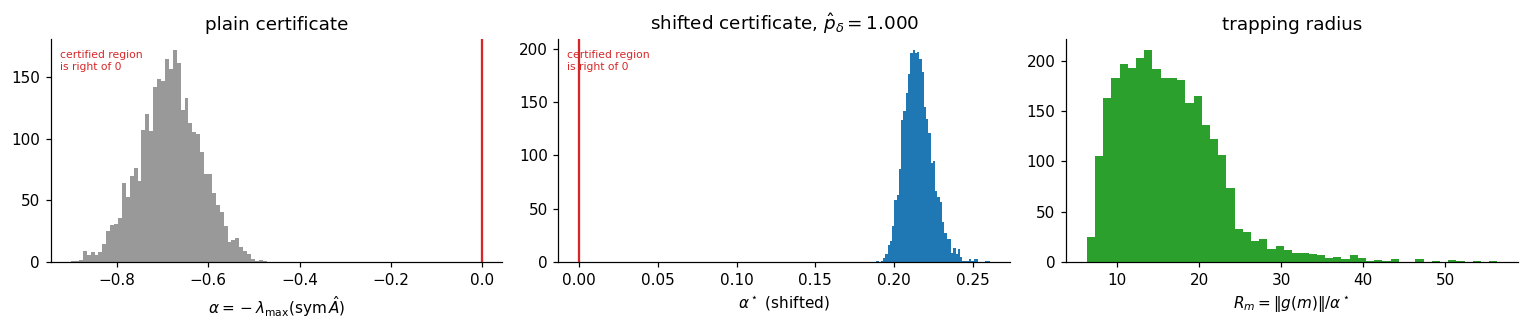

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.1))
axes[0].hist(alpha_plain, bins=50, color="0.6"); axes[0].axvline(0, color="C3")
axes[0].set(xlabel=r"$\alpha=-\lambda_{\max}(\mathrm{sym}\,\hat A)$", title="plain certificate")
axes[1].hist(alpha_shift, bins=50, color="C0"); axes[1].axvline(0, color="C3")
axes[1].set(xlabel=r"$\alpha^\star$ (shifted)",
            title=rf"shifted certificate, $\hat p_\delta={p_hat:.3f}$")
fin = radius[np.isfinite(radius)]
if fin.size:
    axes[2].hist(fin, bins=50, color="C2")
    axes[2].set(xlabel=r"$R_m=\|g(m)\|/\alpha^\star$", title="trapping radius")
for ax in axes[:2]:
    ax.text(0.02, 0.95, "certified region\nis right of 0", transform=ax.transAxes,
            fontsize=7, va="top", color="C3")
plt.tight_layout(); plt.show()

## 5. Prediction

The certified set is non-empty here, so the draws integrated below are the certified ones ---
which, with $\hat p_\delta=1$, is the posterior as it stands. Each is integrated over the whole
horizon, including the prediction window $t\in(2,4]$ that no data came from, and at a parameter
value $(a^\star,b^\star)$ outside the training set.

In [14]:
def compress(Q):    return V.T @ (Q - q_bar[:, None])
def decompress(Qh): return q_bar[:, None] + V @ Qh

def integrate(theta, q0):
    '''Solve dq/dt = O d(q) on t_truth.  Returns None if the solver fails.'''
    O = theta.reshape(r, dof)
    sol = solve_ivp(lambda t, q: O @ features(q), (0, t_truth[-1]), q0,
                    t_eval=t_truth, method="RK45", rtol=1e-8, atol=1e-10)
    if (not sol.success) or sol.y.shape[1] != t_truth.size:
        return None
    return sol.y

def label(params): return f"({params[0]:g}, {params[1]:g})"

CASES = [(tuple(float(v) for v in TRAIN[l]), TRUTH_TR[l]) for l in range(L)]
CASES.append((tuple(float(v) for v in TEST), TRUTH_TE))

mask_tr = t_truth <= T_TRAIN      # observation window
mask_pr = t_truth >  T_TRAIN      # prediction window, no data taken there

def errors(Qpred, truth):
    e_tr = np.linalg.norm(Qpred[:, mask_tr]-truth[:, mask_tr])/np.linalg.norm(truth[:, mask_tr])
    e_pr = np.linalg.norm(Qpred[:, mask_pr]-truth[:, mask_pr])/np.linalg.norm(truth[:, mask_pr])
    return e_tr, e_pr

def energy(Q):  return 0.5*(Q**2).sum(axis=0)*dx**2

pred_draws = theta_samples[:N_PRED]
t0 = time.time()
ENS = []
for params, truth in CASES:
    q0 = compress(truth[:, :1]).ravel()
    runs = [y for y in (integrate(th, q0) for th in pred_draws) if y is not None]
    ENS.append(np.array(runs))
print(f"{sum(e.shape[0] for e in ENS)} ROM solves in {time.time()-t0:.1f} s")
print("draws reaching t = 4:", [e.shape[0] for e in ENS], f"of {N_PRED}")

1200 ROM solves in 3.1 s
draws reaching t = 4: [200, 200, 200, 200, 200, 200] of 200


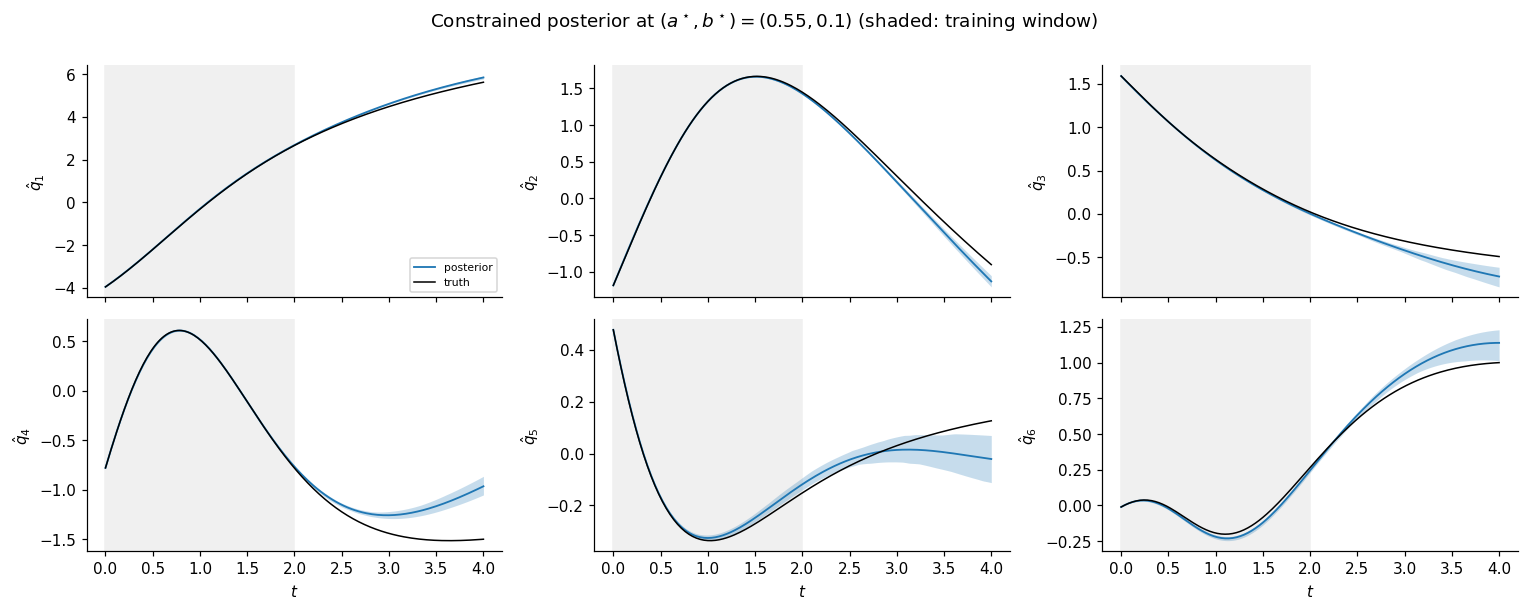

In [15]:
# Reduced coordinates on the held-out trajectory: mean and 95 % band against the truth.
params, truth = CASES[-1]; ens = ENS[-1]
qh_true = compress(truth)
lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5), sharex=True)
for i, ax in enumerate(axes.ravel()[:min(6, r)]):
    ax.fill_between(t_truth, lo_b[i], hi_b[i], color="C0", alpha=0.25, lw=0)
    ax.plot(t_truth, ens.mean(axis=0)[i], "C0", lw=1.2, label="posterior")
    ax.plot(t_truth, qh_true[i], "k", lw=1, label="truth")
    ax.axvspan(0, T_TRAIN, color="0.94", zorder=-1)
    ax.set(ylabel=rf"$\hat q_{{{i+1}}}$")
    if i == 0: ax.legend(fontsize=7)
for ax in axes[-1]: ax.set_xlabel("$t$")
fig.suptitle(rf"Constrained posterior at $(a^\star,b^\star)={params}$ (shaded: training window)", y=1.0)
plt.tight_layout(); plt.show()

## 6. Comparison: the unconstrained posterior

The GP-BayesOpInf baseline: same data, same pipeline, constraint removed, prior scales
re-selected under its own model (eq. (4) with $\mathbf T=\mathbf I$).

In [16]:
def log_evidence_unc(gam):
    '''Eq. (4) with T = I.  P0 is diagonal and P block diagonal, so this splits by row.'''
    g2 = prior_scales(gam)**2
    total = 0.0
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        P  = DWD[i] + np.diag(g2[block])
        signP, logdet_P = np.linalg.slogdet(P)
        if signP <= 0:
            return -1e12
        mu_i = solve(P, DWz[i], assume_a="pos")
        total += 0.5*np.sum(np.log(g2[block])) - 0.5*logdet_P + 0.5*(mu_i @ (P @ mu_i))
    return -0.5*Nobs*np.log(2*np.pi) + 0.5*logdet_W - 0.5*z_W_z + total

t0 = time.time(); best_u = None
for log_gamma_0 in ([-2.]*3, [0.]*3, [2.]*3):
    res = minimize(lambda lg: -log_evidence_unc(np.exp(lg)), log_gamma_0,
                   method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3, maxfev=2000))
    if best_u is None or res.fun < best_u.fun:
        best_u = res
gamma_u = np.exp(best_u.x)
print(f"unconstrained evidence {-best_u.fun:.2f} in {time.time()-t0:.1f} s")
print(f"   gamma = {np.array2string(gamma_u, precision=4)}   "
      f"(constrained: {np.array2string(gamma, precision=4)})")

gvec_u = prior_scales(gamma_u)
mu_u = np.zeros(n); Lchol_u = []
for i in range(r):
    block = slice(i*dof, (i+1)*dof)
    Sig_i = np.linalg.inv(DWD[i] + np.diag(gvec_u[block]**2))
    Sig_i = 0.5*(Sig_i + Sig_i.T)
    mu_u[block] = Sig_i @ DWz[i]
    Lchol_u.append(cholesky(Sig_i + 1e-14*np.eye(dof), lower=True))

def draw_unc(rng):
    theta = np.zeros(n)
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        theta[block] = mu_u[block] + Lchol_u[i] @ rng.standard_normal(dof)
    return theta

rng = np.random.default_rng(SEED)
theta_u = np.array([draw_unc(rng) for _ in range(N_PRED)])

def ep_residual(theta):
    '''Relative |q' H (q (x) q)| over random states: how far from energy preserving.'''
    H = expand_H(unpack(theta)[2])
    rng_q = np.random.default_rng(0); qs = rng_q.standard_normal((100, r))
    return (np.mean([abs(q @ (H @ np.kron(q, q))) for q in qs])
            / np.mean([np.linalg.norm(q)**3 for q in qs]))

print(f"\nrelative |q' H (q x q)| :  constrained {ep_residual(mu_c):.3e}, "
      f"unconstrained {ep_residual(mu_u):.3e}")

unconstrained evidence 5141.44 in 0.1 s
   gamma = [0.5334 1.3184 6.0465]   (constrained: [0.749  2.0981 7.3117])

relative |q' H (q x q)| :  constrained 1.015e-15, unconstrained 1.087e-01


In [17]:
t0 = time.time()
ENS_U = []
for params, truth in CASES:
    q0 = compress(truth[:, :1]).ravel()
    runs = [y for y in (integrate(th, q0) for th in theta_u) if y is not None]
    ENS_U.append(np.array(runs))
print(f"{sum(e.shape[0] for e in ENS_U)} baseline solves in {time.time()-t0:.1f} s")

823 baseline solves in 9.3 s


### 6.1 The table

Relative state error of the ensemble mean over the $200$ draws, on the observation window
$[0,2]$ and on the prediction window $(2,4]$ from which no data were taken, with the
projection error of the full-order solution as the attainable floor. Diverged draws are
excluded from the ensemble mean that reports them, which flatters the posterior they came
from; the count is given underneath.

In [18]:
hdr = f"[0,{T_TRAIN:g}]", f"({T_TRAIN:g},{T_FINAL:g}]"
print(f"{'(a,b)':>14s} | {'constrained':^19s} | {'unconstrained':^19s} | {'projection floor':^19s}")
print(f"{'':>14s} | {hdr[0]:>9s} {hdr[1]:>9s} | {hdr[0]:>9s} {hdr[1]:>9s} | {hdr[0]:>9s} {hdr[1]:>9s}")
rows_tab = []
for (params, truth), ens_c, ens_u in zip(CASES, ENS, ENS_U):
    e1c, e2c = errors(decompress(ens_c.mean(axis=0)), truth) if ens_c.size else (np.nan, np.nan)
    e1u, e2u = errors(decompress(ens_u.mean(axis=0)), truth) if ens_u.size else (np.nan, np.nan)
    p1,  p2  = errors(decompress(compress(truth)), truth)
    star = "  <- test" if params == CASES[-1][0] else ""
    def fmt(v): return f"{v:9.4f}" if np.isfinite(v) else f"{'--':>9s}"
    print(f"{label(params):>14s} | {fmt(e1c)} {fmt(e2c)} | {fmt(e1u)} {fmt(e2u)} | "
          f"{p1:9.4f} {p2:9.4f}{star}")
    rows_tab.append((params, e1c, e2c, e1u, e2u, p1, p2, ens_c.shape[0], ens_u.shape[0]))
fin = lambda j: np.nanmean([row[j] for row in rows_tab])
print(f"{'mean':>14s} | {fin(1):9.4f} {fin(2):9.4f} | {fin(3):9.4f} {fin(4):9.4f} | "
      f"{fin(5):9.4f} {fin(6):9.4f}")

print(f"\n{'(a,b)':>14s} " + " ".join(f"{label(p):>12s}" for p, *_ in rows_tab))
print(f"{'diverged (constrained)':>14s} "
      + " ".join(f"{N_PRED-row[7]:12d}" for row in rows_tab))
print(f"{'diverged (unconstrained)':>14s} "
      + " ".join(f"{N_PRED-row[8]:12d}" for row in rows_tab))

         (a,b) |     constrained     |    unconstrained    |  projection floor  
               |     [0,2]     (2,4] |     [0,2]     (2,4] |     [0,2]     (2,4]
      (0.4, 0) |    0.0144    0.0550 |    0.0153    0.0962 |    0.0144    0.0452
      (0.6, 0) |    0.0179    0.1656 |    0.0821    0.5803 |    0.0177    0.1517
    (0.4, 0.4) |    0.0137    0.0596 |    0.0142    0.1167 |    0.0135    0.0528
    (0.6, 0.4) |    0.0229    0.1796 |    0.0232    0.2239 |    0.0228    0.1748
    (0.5, 0.2) |    0.0122    0.0946 |    0.0127    0.1691 |    0.0121    0.0865
   (0.55, 0.1) |    0.0138    0.1243 |    0.0318   10.6273 |    0.0134    0.1146  <- test
          mean |    0.0158    0.1131 |    0.0299    1.9689 |    0.0156    0.1043

         (a,b)     (0.4, 0)     (0.6, 0)   (0.4, 0.4)   (0.6, 0.4)   (0.5, 0.2)  (0.55, 0.1)
diverged (constrained)            0            0            0            0            0            0
diverged (unconstrained)            0          124            0    

### 6.2 Energy

The full-order energy $E(t)=\tfrac12\|\mathbf w\|^2\Delta x^2$ decreases monotonically: convection
moves no energy and viscosity removes it. A reduced model inherits that only if its quadratic
part is energy preserving, so the lifted prediction is a direct test of the structure --- one
that does not go through accuracy, and so is not masked by the projection error.

In [19]:
def energy_report(ens):
    '''Worst relative increase of E over one step, and how many draws never increase it.'''
    if ens.size == 0:
        return np.nan, 0, 0
    worst = -np.inf; monotone = 0
    for y in ens:
        E = energy(decompress(y))
        rise = np.diff(E).max()/E[0]
        worst = max(worst, rise)
        monotone += bool(rise <= 1e-12)
    return worst, monotone, ens.shape[0]

print(f"{'(a,b)':>14s} | {'constrained':^28s} | {'unconstrained':^28s}")
print(f"{'':>14s} | {'worst rise':>14s} {'monotone':>12s} | {'worst rise':>14s} {'monotone':>12s}")
energy_tab = []
for (params, truth), ens_c, ens_u in zip(CASES, ENS, ENS_U):
    wc, mc, nc = energy_report(ens_c)
    wu, mu_, nu_ = energy_report(ens_u)
    print(f"{label(params):>14s} | {wc:14.2e} {f'{mc}/{nc}':>12s} | "
          f"{wu:14.2e} {f'{mu_}/{nu_}':>12s}")
    energy_tab.append((params, wc, mc, nc, wu, mu_, nu_))
E_true_rise = max(np.diff(energy(truth)).max()/energy(truth)[0] for _, truth in CASES)
print(f"\nthe full-order solutions themselves: worst rise {E_true_rise:.2e} (round-off)")

         (a,b) |         constrained          |        unconstrained        
               |     worst rise     monotone |     worst rise     monotone
      (0.4, 0) |      -1.95e-03      200/200 |       5.33e-03       98/200
      (0.6, 0) |      -1.81e-03      200/200 |       8.86e+02        43/76
    (0.4, 0.4) |      -1.67e-03      200/200 |       1.34e-01      101/200
    (0.6, 0.4) |      -1.55e-03      200/200 |       3.38e+03       92/133
    (0.5, 0.2) |      -1.83e-03      200/200 |       3.49e+02       79/178
   (0.55, 0.1) |      -1.84e-03      200/200 |       2.71e+06         5/36

the full-order solutions themselves: worst rise -1.39e-03 (round-off)


In [20]:
# Uncertainty: does the 95 % band cover the projected truth, and how wide is it?
def coverage_and_width(ens, truth):
    qh = compress(truth)
    lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
    inside = (qh >= lo_b) & (qh <= hi_b)
    width  = hi_b - lo_b
    return (inside[:, mask_tr].mean(), inside[:, mask_pr].mean(),
            np.median(width[:, mask_tr]), np.median(width[:, mask_pr]))

print(f"{'(a,b)':>14s} | {'coverage of the 95% band':^25s} | {'median band width':^21s}")
print(f"{'':>14s} | {hdr[0]:>12s} {hdr[1]:>12s} | {hdr[0]:>10s} {hdr[1]:>10s}")
cover_tab = []
for (params, truth), ens in zip(CASES, ENS):
    c_tr, c_pr, w_tr, w_pr = coverage_and_width(ens, truth)
    print(f"{label(params):>14s} | {c_tr:12.3f} {c_pr:12.3f} | {w_tr:10.3f} {w_pr:10.3f}")
    cover_tab.append((params, c_tr, c_pr, w_tr, w_pr))

         (a,b) | coverage of the 95% band  |   median band width  
               |        [0,2]        (2,4] |      [0,2]      (2,4]
      (0.4, 0) |        0.705        0.210 |      0.006      0.030
      (0.6, 0) |        0.487        0.197 |      0.017      0.116
    (0.4, 0.4) |        0.348        0.270 |      0.010      0.025
    (0.6, 0.4) |        0.630        0.243 |      0.020      0.094
    (0.5, 0.2) |        0.483        0.273 |      0.013      0.043
   (0.55, 0.1) |        0.427        0.118 |      0.015      0.070


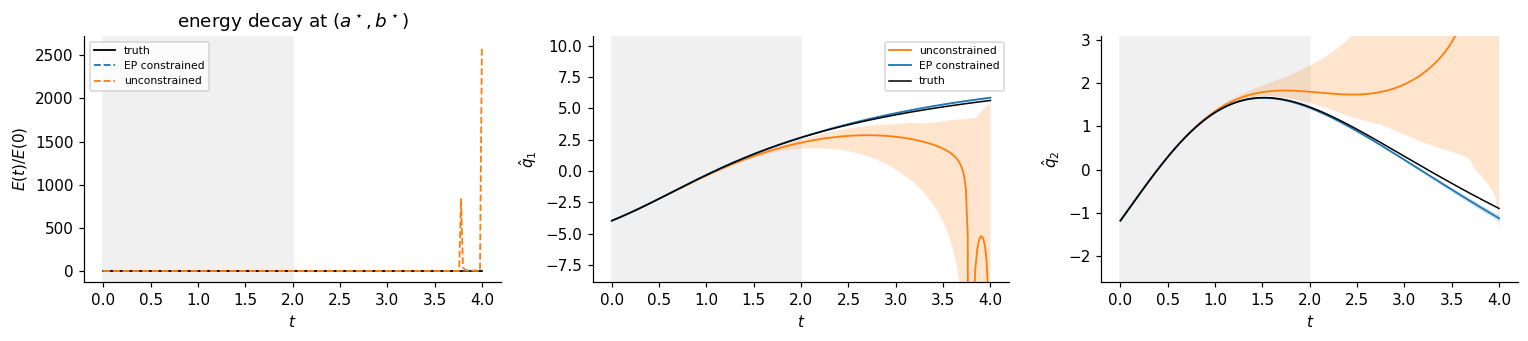

In [21]:
# The energy of the predicted fields, which the true solution loses monotonically, and the
# two posteriors in the two leading reduced coordinates.
params, truth = CASES[-1]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
E_true = energy(truth)
axes[0].plot(t_truth, E_true/E_true[0], "k", lw=1.2, label="truth")
for ens, color, name in ((ENS[-1], "C0", "EP constrained"), (ENS_U[-1], "C1", "unconstrained")):
    if ens.size == 0: continue
    E = energy(decompress(ens.mean(axis=0)))
    axes[0].plot(t_truth, E/E[0], color=color, ls="--", lw=1.2, label=name)
axes[0].axvspan(0, T_TRAIN, color="0.94", zorder=-1)
axes[0].set(xlabel="$t$", ylabel="$E(t)/E(0)$", title="energy decay at $(a^\\star,b^\\star)$")
axes[0].legend(fontsize=7)

qh_true = compress(truth)
for i, ax in enumerate(axes[1:]):
    for ens, color, name in ((ENS_U[-1], "C1", "unconstrained"), (ENS[-1], "C0", "EP constrained")):
        if ens.size == 0: continue
        lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
        ax.fill_between(t_truth, lo_b[i], hi_b[i], color=color, alpha=0.2, lw=0)
        ax.plot(t_truth, ens.mean(axis=0)[i], color=color, lw=1.2, label=name)
    ax.plot(t_truth, qh_true[i], "k", lw=1, label="truth")
    ax.axvspan(0, T_TRAIN, color="0.94", zorder=-1)
    span = np.concatenate([qh_true[i], ENS[-1].mean(axis=0)[i]])
    pad = 0.5*(span.max() - span.min() + 1e-12)
    ax.set_ylim(span.min()-pad, span.max()+pad)
    ax.set(xlabel="$t$", ylabel=rf"$\hat q_{{{i+1}}}$")
    if i == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. The predicted fields

The held-out parameter value $(a^\star,b^\star)$, at the end of the training window and at the two
later times the prediction has to reach on its own. Columns: the full-order solution, the
posterior mean lifted back to the $2500$ nodes, the error, and the pointwise standard deviation
over the draws. The first two columns share a colour scale, and so do the last two.

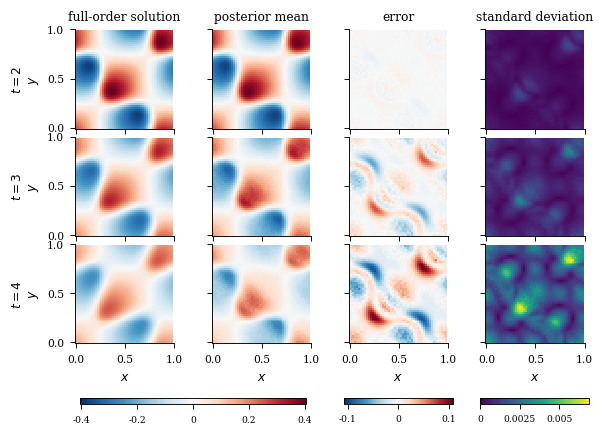

    t  relative field error   mean std / field rms
  2.0                0.0128                 0.0016
  3.0                0.1157                 0.0051
  4.0                0.2486                 0.0165


In [22]:
import matplotlib as mpl

PAPER_RC = {
    "font.family": "serif", "font.size": 8,
    "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "lines.linewidth": 1.0, "pdf.fonttype": 42,
}
C_CON, C_UNC, C_SKEW = "#0072B2", "#D55E00", "#009E73"

params, truth = CASES[-1]; ens = ENS[-1]
times_show = [T_TRAIN, 1.5*T_TRAIN, 2.0*T_TRAIN]
X_grid, Y_grid = np.meshgrid(x, y, indexing="ij")

# Lift every draw at the three times: (n_draws, n) -> mean and standard deviation per node.
lifted = {}
for t_show in times_show:
    j = int(np.argmin(np.abs(t_truth - t_show)))
    full = q_bar[:, None] + V @ ens[:, :, j].T          # (2500, n_draws)
    lifted[t_show] = (truth[:, j], full.mean(axis=1), full.std(axis=1))

field_max = max(np.abs(np.concatenate([lifted[t][0] for t in times_show])).max(),
                np.abs(np.concatenate([lifted[t][1] for t in times_show])).max())
err_max   = max(np.abs(lifted[t][0]-lifted[t][1]).max() for t in times_show)
std_max   = max(lifted[t][2].max() for t in times_show)

with plt.rc_context(PAPER_RC):
    fig, axes = plt.subplots(3, 4, figsize=(6.3, 4.6),
                             gridspec_kw=dict(wspace=0.08, hspace=0.08))
    titles = ["full-order solution", "posterior mean", "error", "standard deviation"]
    for row_i, t_show in enumerate(times_show):
        w_true, w_mean, w_std = lifted[t_show]
        panels = [(w_true,          "RdBu_r", -field_max, field_max),
                  (w_mean,          "RdBu_r", -field_max, field_max),
                  (w_true - w_mean, "RdBu_r", -err_max,   err_max),
                  (w_std,           "viridis", 0.0,       std_max)]
        for col_i, (field, cmap, vmin, vmax) in enumerate(panels):
            ax = axes[row_i, col_i]
            im = ax.pcolormesh(X_grid, Y_grid, field.reshape(NX, NX), shading="auto",
                               cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True)
            ax.set(aspect="equal", xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
            if row_i == 0: ax.set_title(titles[col_i])
            if col_i == 0: ax.set_ylabel(f"$t = {t_show:g}$\n$y$")
            else:          ax.set_yticklabels([])
            if row_i == 2: ax.set_xlabel("$x$")
            else:          ax.set_xticklabels([])
            if row_i == 2 and col_i != 0:       # colour bars underneath: one for the
                cols = axes[:, 0:2] if col_i == 1 else axes[:, col_i]   # two field
                cb = fig.colorbar(im, ax=cols, location="bottom",       # columns, one
                                  fraction=0.055, pad=0.14, shrink=0.86,  # each for
                                  aspect=34 if col_i == 1 else 17)        # the rest
                cb.ax.tick_params(labelsize=6)
                cb.ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    fig.savefig("fig_prob3_fields.pdf", bbox_inches="tight", dpi=300)
    plt.show()

print(f"{'t':>5s} {'relative field error':>21s} {'mean std / field rms':>22s}")
for t_show in times_show:
    w_true, w_mean, w_std = lifted[t_show]
    print(f"{t_show:5.1f} {np.linalg.norm(w_true-w_mean)/np.linalg.norm(w_true):21.4f} "
          f"{w_std.mean()/np.sqrt(np.mean(w_true**2)):22.4f}")

## 8. Save

In [23]:
def summarize(ens):
    if ens.size == 0:
        return np.full((3, r, t_truth.size), np.nan)
    return np.stack([ens.mean(axis=0),
                     np.percentile(ens, 2.5, axis=0),
                     np.percentile(ens, 97.5, axis=0)])

np.savez_compressed(
    "results_Burgers2D.npz",
    r=r, seed=SEED, n_samp=N_SAMP, n_pred=N_PRED, delta=DELTA,
    gamma=gamma, gamma_unc=gamma_u,
    theta_mean=mu_c, theta_mean_unc=mu_u,
    alpha=alpha_plain, alpha_star=alpha_shift, radius=radius,
    p_hat=p_hat, cp_interval=np.array([lo, hi]), centre=centre, n_positive=n_positive,
    case_params=np.array([p for p, *_ in rows_tab]),
    ens_summary=np.stack([summarize(e) for e in ENS]),
    ens_summary_unc=np.stack([summarize(e) for e in ENS_U]),
    errors=np.array([[row[1], row[2], row[3], row[4]] for row in rows_tab]),
    floors=np.array([[row[5], row[6]] for row in rows_tab]),
    survivors=np.array([[row[7], row[8]] for row in rows_tab]),
    coverage=np.array([[c1, c2, w1, w2] for _, c1, c2, w1, w2 in cover_tab]),
    energy_rise=np.array([[row[1], row[4]] for row in energy_tab]),
    energy_monotone=np.array([[row[2], row[5]] for row in energy_tab]),
    deriv_rel_err=rel_err, deriv_abs_err=abs_err, deriv_rms=deriv_rms,
    fields=np.array([np.stack(lifted[t]) for t in times_show]),
    fields_times=np.array(times_show),
)
import os
print(f"saved results_Burgers2D.npz  ({os.path.getsize('results_Burgers2D.npz')/2**20:.1f} MiB)")

saved results_Burgers2D.npz  (0.7 MiB)
